## Classical feedforward and control flow (dynamic circuits)
https://quantum.cloud.ibm.com/docs/en/qiskit/classical-feedforward-and-control-flow

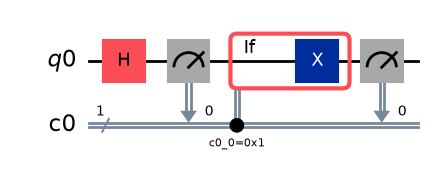

In [1]:
# if statement

from qiskit.circuit import QuantumCircuit, QuantumRegister, ClassicalRegister

qubits = QuantumRegister(1)
clbits = ClassicalRegister(1)
circuit = QuantumCircuit(qubits, clbits)
(q0,) = qubits
(c0,) = clbits

circuit.h(q0)
circuit.measure(q0, c0)
with circuit.if_test((c0, 1)):
    circuit.x(q0)
circuit.measure(q0, c0)
circuit.draw("mpl")

# example output counts: {'0': 1024}

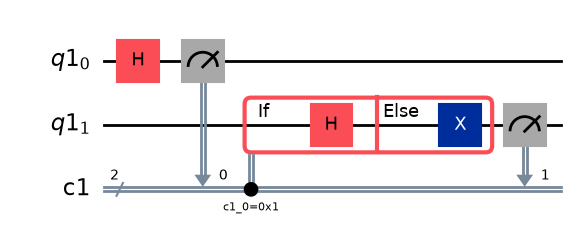

In [2]:
qubits = QuantumRegister(2)
clbits = ClassicalRegister(2)
circuit = QuantumCircuit(qubits, clbits)
(q0, q1) = qubits
(c0, c1) = clbits

circuit.h(q0)
circuit.measure(q0, c0)
with circuit.if_test((c0, 1)) as else_:
    circuit.h(q1)
with else_:
    circuit.x(q1)
circuit.measure(q1, c1)

circuit.draw("mpl")

# example output counts: {'01': 260, '11': 272, '10': 492}

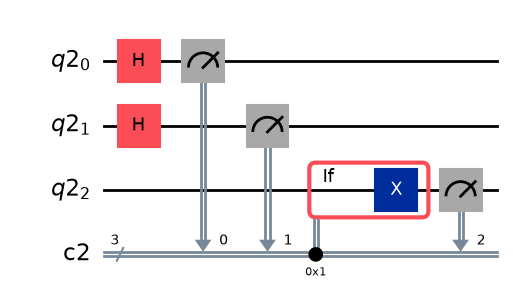

In [3]:
qubits = QuantumRegister(3)
clbits = ClassicalRegister(3)
circuit = QuantumCircuit(qubits, clbits)
(q0, q1, q2) = qubits
(c0, c1, c2) = clbits

circuit.h([q0, q1])
circuit.measure(q0, c0)
circuit.measure(q1, c1)
with circuit.if_test((clbits, 0b001)):
    circuit.x(q2)
circuit.measure(q2, c2)

circuit.draw("mpl")

# example output counts: {'101': 269, '011': 260, '000': 252, '010': 243}

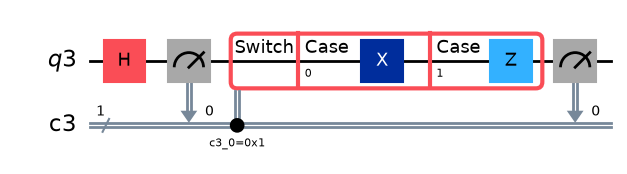

In [4]:
# Switch statement

qubits = QuantumRegister(1)
clbits = ClassicalRegister(1)
circuit = QuantumCircuit(qubits, clbits)
(q0,) = qubits
(c0,) = clbits

circuit.h(q0)
circuit.measure(q0, c0)
with circuit.switch(c0) as case:
    with case(0):
        circuit.x(q0)
    with case(1):
        circuit.z(q0)
circuit.measure(q0, c0)

circuit.draw("mpl")

# example output counts: {'1': 1024}

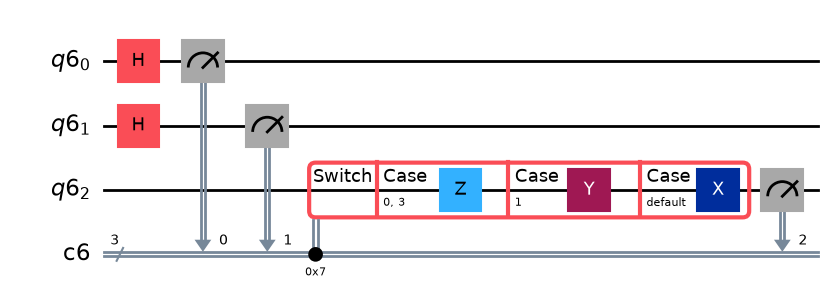

In [7]:
qubits = QuantumRegister(3)
clbits = ClassicalRegister(3)
circuit = QuantumCircuit(qubits, clbits)
(q0, q1, q2) = qubits
(c0, c1, c2) = clbits

circuit.h([q0, q1])
circuit.measure(q0, c0)
circuit.measure(q1, c1)
with circuit.switch(clbits) as case:
    with case(0b000, 0b011):
        circuit.z(q2)
    with case(0b001):
        circuit.y(q2)
    with case(case.DEFAULT):
        circuit.x(q2)
circuit.measure(q2, c2)

circuit.draw("mpl")

# example output counts: {'101': 267, '110': 249, '011': 265, '000': 243}

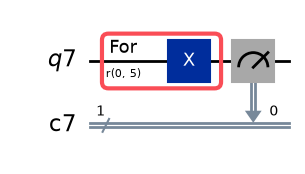

In [8]:
# For loop

qubits = QuantumRegister(1)
clbits = ClassicalRegister(1)
circuit = QuantumCircuit(qubits, clbits)
(q0,) = qubits
(c0,) = clbits

with circuit.for_loop(range(5)) as _:
    circuit.x(q0)
circuit.measure(q0, c0)

circuit.draw("mpl")

# example output counts: {'1': 1024}

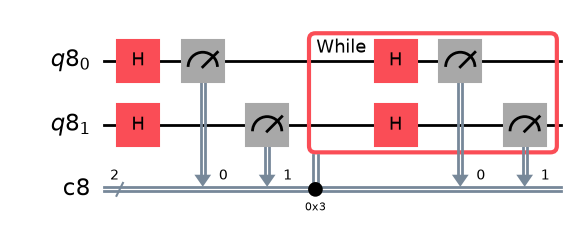

In [9]:
# While loop

qubits = QuantumRegister(2)
clbits = ClassicalRegister(2)
circuit = QuantumCircuit(qubits, clbits)

q0, q1 = qubits
c0, c1 = clbits

circuit.h([q0, q1])
circuit.measure(q0, c0)
circuit.measure(q1, c1)
with circuit.while_loop((clbits, 0b11)):
    circuit.h([q0, q1])
    circuit.measure(q0, c0)
    circuit.measure(q1, c1)

circuit.draw("mpl")

# example output counts: {'01': 334, '10': 368, '00': 322}

In [10]:
# Classical expressions

from qiskit import QuantumCircuit, QuantumRegister, ClassicalRegister
from qiskit.circuit.classical import expr

num_qubits = 8
if num_qubits % 2 or num_qubits < 4:
    raise ValueError("num_qubits must be an even integer ≥ 4")
meas_qubits = list(range(2, num_qubits, 2))  # qubits to measure and reset

qr = QuantumRegister(num_qubits, "qr")
mr = ClassicalRegister(len(meas_qubits), "m")
qc = QuantumCircuit(qr, mr)

# Create local Bell pairs
qc.reset(qr)
qc.h(qr[::2])
for ctrl in range(0, num_qubits, 2):
    qc.cx(qr[ctrl], qr[ctrl + 1])

# Glue neighboring pairs
for ctrl in range(1, num_qubits - 1, 2):
    qc.cx(qr[ctrl], qr[ctrl + 1])

# Measure boundary qubits between pairs,reset to 0
for k, q in enumerate(meas_qubits):
    qc.measure(qr[q], mr[k])
    qc.reset(qr[q])

# Parity-conditioned X corrections
# Each non-measured qubit gets flipped iff the parity (XOR) of all
# preceding measurement bits is 1
for tgt in range(num_qubits):
    if tgt in meas_qubits:  # skip measured qubits
        continue
    # all measurement registers whose physical qubit index < tgt
    left_bits = [k for k, q in enumerate(meas_qubits) if q < tgt]
    if not left_bits:  # skip if list empty
        continue

    # build XOR-parity expression
    parity = expr.lift(
        mr[left_bits[0]]
    )  # lift the first bit to Value so it will be treated like a boolean.
    for k in left_bits[1:]:
        parity = expr.bit_xor(
            mr[k], parity
        )  # calculate parity with all other bits
    with qc.if_test(parity):  # Add X if parity is 1
        qc.x(qr[tgt])

# Re-entangle measured qubits
for ctrl in range(1, num_qubits - 1, 2):
    qc.cx(qr[ctrl], qr[ctrl + 1])

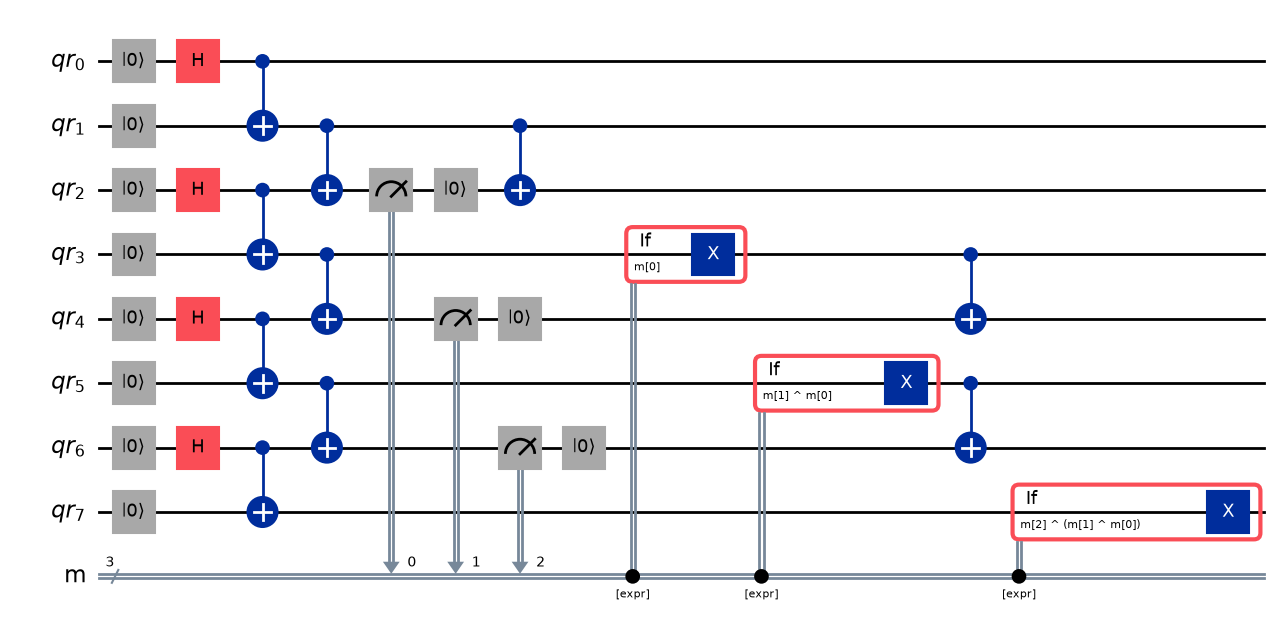

In [11]:
qc.draw(output="mpl", style="iqp", idle_wires=False, fold=-1)

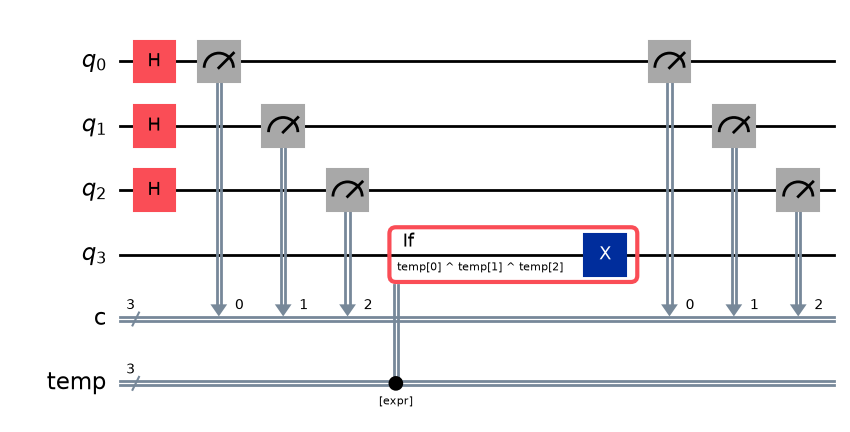

In [12]:
# Store

from qiskit.circuit import QuantumCircuit, QuantumRegister, ClassicalRegister
from qiskit.circuit.classical import expr

qregs = QuantumRegister(4, "q")
creg = ClassicalRegister(3, "c")
# temp is a plain ClassicalRegister used as the store target
temp = ClassicalRegister(3, "temp")
qc = QuantumCircuit(qregs, creg, temp)

qc.h([0, 1, 2])
qc.measure([0, 1, 2], creg)

# Store bit-NOT of the full 3-bit register into temp
qc.store(temp, expr.bit_not(creg))

# Compute parity of temp using bit-indexed XOR
parity = expr.bit_xor(
    expr.bit_xor(expr.index(temp, 0), expr.index(temp, 1)),
    expr.index(temp, 2),
)

# Flip q3 if parity of ~creg is 1
with qc.if_test(parity):
    qc.x(3)

qc.measure([0, 1, 2], creg)

qc.draw("mpl")